# Final Project: Classify Waste Products Using Transfer Learning
**Course:** Deep Learning with Keras and TensorFlow (IBM, Coursera)
**Author:** Saleh Khaled Saleh Alzhrani

**Goal:** Build an image classifier that sorts waste photos into two classes:
- **O** = Organic waste
- **R** = Recyclable waste

**Method:** Transfer learning with the **VGG16** network (pre-trained on ImageNet), in two ways:
1. **Extract Features model**: VGG16 is frozen and only the new top layers are trained.
2. **Fine-Tuned model**: the last convolution block of VGG16 (`block5_conv3`) is also unfrozen and trained.

## 1. Install and import libraries

In [1]:
# Run this cell once. If the libraries are already installed it finishes quickly.
%pip install -q tensorflow==2.17.0 numpy matplotlib scikit-learn requests tqdm

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import glob
import zipfile
from pathlib import Path

import numpy as np
import requests
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn import metrics

import tensorflow as tf
from tensorflow.keras import optimizers
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.applications import vgg16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, LearningRateScheduler

import warnings
warnings.filterwarnings("ignore")

2026-11-24 05:58:00.633665: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-24 05:58:00.634958: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 05:58:00.639570: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 05:58:00.652225: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-24 05:58:00.672548: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

### Task 1: Print the version of TensorFlow

In [2]:
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.17.0


## 2. Download and unzip the dataset

In [3]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/kd6057VPpABQ2FqCbgu9YQ/o-vs-r-split-reduced-1200.zip"
file_name = "o-vs-r-split-reduced-1200.zip"

if not os.path.exists("o-vs-r-split"):
    print("Downloading the dataset...")
    with requests.get(url, stream=True) as response:
        response.raise_for_status()
        with open(file_name, "wb") as f:
            for chunk in tqdm(response.iter_content(chunk_size=8192)):
                f.write(chunk)
    print("Extracting...")
    with zipfile.ZipFile(file_name, "r") as zip_ref:
        zip_ref.extractall(".")
    os.remove(file_name)
print("Dataset ready. Folders:", os.listdir("o-vs-r-split"))

Dataset ready. Folders: ['test', 'train']


## 3. Settings (model parameters)

In [4]:
img_rows, img_cols = 150, 150      # every image is resized to 150 x 150 pixels
batch_size = 32                    # images per training step
n_epochs = 10                      # passes over the data
n_classes = 2                      # O and R
val_split = 0.2                    # 20% of the training folder is used for validation
verbosity = 1
path = "o-vs-r-split/train/"
path_test = "o-vs-r-split/test/"
input_shape = (img_rows, img_cols, 3)   # 3 = RGB colour channels
labels = ["O", "R"]
seed = 42                          # makes the random split repeatable

## 4. Data generators

In [5]:
# Training images: rescale pixels to 0-1 and add light augmentation
train_datagen = ImageDataGenerator(
    validation_split=val_split,
    rescale=1.0 / 255.0,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
)

# Validation images: rescale only (no augmentation)
val_datagen = ImageDataGenerator(
    validation_split=val_split,
    rescale=1.0 / 255.0,
)

# Test images: rescale only
test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

In [6]:
train_generator = train_datagen.flow_from_directory(
    path,
    seed=seed,
    batch_size=batch_size,
    class_mode="binary",
    shuffle=True,
    target_size=(img_rows, img_cols),
    subset="training",
)

val_generator = val_datagen.flow_from_directory(
    path,
    seed=seed,
    batch_size=batch_size,
    class_mode="binary",
    shuffle=True,
    target_size=(img_rows, img_cols),
    subset="validation",
)

Found 800 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


### Task 2: Create a `test_generator` using the `test_datagen` object

In [7]:
test_generator = test_datagen.flow_from_directory(
    directory=path_test,
    class_mode="binary",
    seed=seed,
    batch_size=batch_size,
    shuffle=False,
    target_size=(img_rows, img_cols),
)

Found 200 images belonging to 2 classes.


### Task 3: Print the length of the `train_generator`

In [8]:
# Number of batches per epoch = number of training images / batch_size (rounded up)
print("Length of train_generator:", len(train_generator))

Length of train_generator: 25


## 5. Build the model (VGG16 used as a frozen feature extractor)

In [9]:
vgg = vgg16.VGG16(include_top=False, weights="imagenet", input_shape=input_shape)

output = vgg.layers[-1].output
output = Flatten()(output)
basemodel = Model(vgg.input, output)

# Freeze every VGG16 layer so its ImageNet weights do not change
for layer in basemodel.layers:
    layer.trainable = False

In [10]:
model = Sequential()
model.add(basemodel)
model.add(Dense(512, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(512, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(1, activation="sigmoid"))   # 1 output: probability that the image is R

### Task 4: Print the summary of the model

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional (Functional)         │ (None, 8192)           │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,172,673 (73.14 MB)

 Trainable params: 4,457,985 (17.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

### Task 5: Compile the model

In [13]:
model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"],
)

## 6. Callbacks and training (Extract Features model)

In [14]:
def exp_decay(epoch):
    # Learning rate shrinks a little every epoch
    initial_lrate = 1e-4
    k = 0.1
    return initial_lrate * np.exp(-k * epoch)

lrate = LearningRateScheduler(exp_decay)

checkpoint_path = "O_R_tlearn_vgg16.keras"
checkpoint = ModelCheckpoint(filepath=checkpoint_path, save_best_only=True, monitor="val_loss", mode="min")
early_stop = EarlyStopping(monitor="val_loss", patience=4, mode="min", min_delta=0.01)

callbacks_list_ = [checkpoint, early_stop, lrate]

In [15]:
extract_feat_model = model.fit(
    train_generator,
    steps_per_epoch=5,
    epochs=n_epochs,
    callbacks=callbacks_list_,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    verbose=verbosity,
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 68s 15s/step - accuracy: 0.5250 - loss: 0.7386 - val_accuracy: 0.6823 - val_loss: 0.5979 - learning_rate: 1.0000e-04
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 64s 15s/step - accuracy: 0.6625 - loss: 0.6157 - val_accuracy: 0.7760 - val_loss: 0.5322 - learning_rate: 9.0484e-05
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 62s 14s/step - accuracy: 0.7937 - loss: 0.4965 - val_accuracy: 0.7344 - val_loss: 0.5027 - learning_rate: 8.1873e-05
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 59s 13s/step - accuracy: 0.8000 - loss: 0.4653 - val_accuracy: 0.8073 - val_loss: 0.4555 - learning_rate: 7.4082e-05
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 58s 13s/step - accuracy: 0.8125 - loss: 0.4819 - val_accuracy: 0.7656 - val_loss: 0.4535 - learning_rate: 6.7032e-05
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 60s 13s/step - accuracy: 0.8313 - loss: 0.4199 - val_accuracy: 0.8333 - val_loss: 0.3998 - learning_rate: 6.0653e-05
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 59s 13s/step - accuracy: 0.7750 - loss: 0.4254

### Loss curves (Extract Features model)

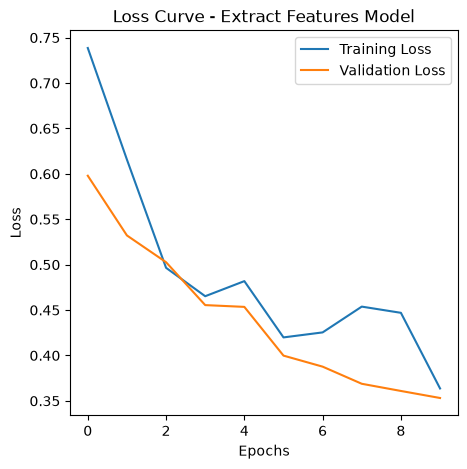

In [16]:
history = extract_feat_model
plt.figure(figsize=(5, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Curve - Extract Features Model")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Task 6: Plot accuracy curves for training and validation sets (extract_feat_model)

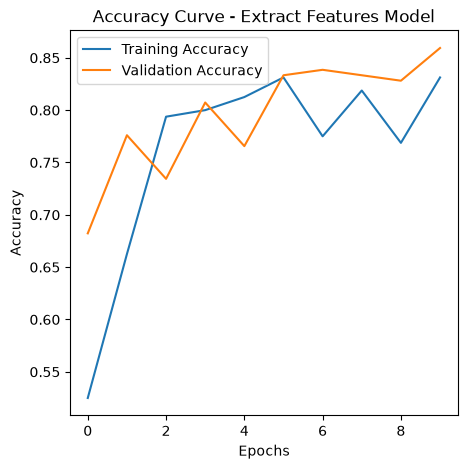

In [17]:
history = extract_feat_model
plt.figure(figsize=(5, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy Curve - Extract Features Model")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## 7. Fine-tuning (unfreeze VGG16 from `block5_conv3` onward)

In [18]:
vgg = vgg16.VGG16(include_top=False, weights="imagenet", input_shape=input_shape)
output = vgg.layers[-1].output
output = Flatten()(output)
basemodel = Model(vgg.input, output)

set_trainable = False
for layer in basemodel.layers:
    if layer.name in ["block5_conv3"]:
        set_trainable = True
    layer.trainable = set_trainable

print([(layer.name, layer.trainable) for layer in basemodel.layers])

[('input_layer_2', False), ('block1_conv1', False), ('block1_conv2', False), ('block1_pool', False), ('block2_conv1', False), ('block2_conv2', False), ('block2_pool', False), ('block3_conv1', False), ('block3_conv2', False), ('block3_conv3', False), ('block3_pool', False), ('block4_conv1', False), ('block4_conv2', False), ('block4_conv3', False), ('block4_pool', False), ('block5_conv1', False), ('block5_conv2', False), ('block5_conv3', True), ('block5_pool', True), ('flatten_1', True)]


In [19]:
model_ft = Sequential()
model_ft.add(basemodel)
model_ft.add(Dense(512, activation="relu"))
model_ft.add(Dropout(0.3))
model_ft.add(Dense(512, activation="relu"))
model_ft.add(Dropout(0.3))
model_ft.add(Dense(1, activation="sigmoid"))

model_ft.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=["accuracy"],
)

In [20]:
checkpoint_path_ft = "O_R_tlearn_fine_tune_vgg16.keras"
checkpoint_ft = ModelCheckpoint(filepath=checkpoint_path_ft, save_best_only=True, monitor="val_loss", mode="min")
early_stop_ft = EarlyStopping(monitor="val_loss", patience=4, mode="min", min_delta=0.01)
callbacks_list_ft = [checkpoint_ft, early_stop_ft, LearningRateScheduler(exp_decay)]

fine_tune_model = model_ft.fit(
    train_generator,
    steps_per_epoch=5,
    epochs=n_epochs,
    callbacks=callbacks_list_ft,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    verbose=verbosity,
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 64s 14s/step - accuracy: 0.5500 - loss: 0.7651 - val_accuracy: 0.8073 - val_loss: 0.5304 - learning_rate: 1.0000e-04
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 59s 13s/step - accuracy: 0.7437 - loss: 0.5333 - val_accuracy: 0.7500 - val_loss: 0.4766 - learning_rate: 9.0484e-05
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 58s 13s/step - accuracy: 0.7688 - loss: 0.5060 - val_accuracy: 0.8229 - val_loss: 0.4007 - learning_rate: 8.1873e-05
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 56s 13s/step - accuracy: 0.7812 - loss: 0.4081 - val_accuracy: 0.7812 - val_loss: 0.4342 - learning_rate: 7.4082e-05
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 62s 14s/step - accuracy: 0.8125 - loss: 0.3861 - val_accuracy: 0.8646 - val_loss: 0.3238 - learning_rate: 6.7032e-05
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 59s 13s/step - accuracy: 0.7812 - loss: 0.4222 - val_accuracy: 0.8646 - val_loss: 0.3279 - learning_rate: 6.0653e-05
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 58s 13s/step - accuracy: 0.8188 - loss: 0.3808

### Task 7: Plot loss curves for training and validation sets (fine tune model)

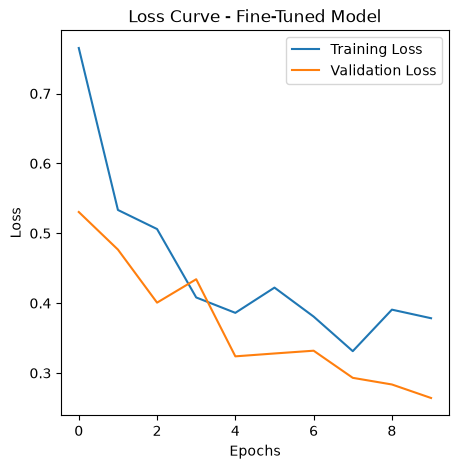

In [21]:
history = fine_tune_model
plt.figure(figsize=(5, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss Curve - Fine-Tuned Model")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Task 8: Plot accuracy curves for training and validation sets (fine tune model)

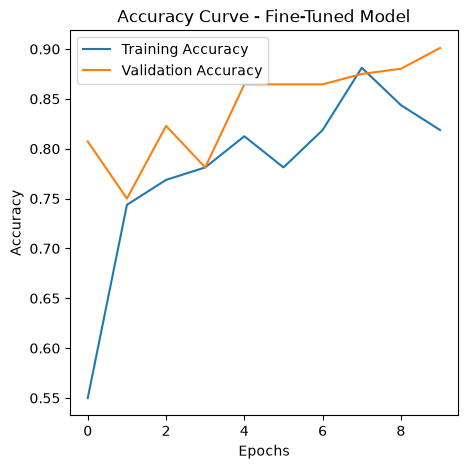

In [22]:
history = fine_tune_model
plt.figure(figsize=(5, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy Curve - Fine-Tuned Model")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## 8. Evaluate both models on test images

In [23]:
# Load the best saved version of each model
extract_feat_loaded = tf.keras.models.load_model("O_R_tlearn_vgg16.keras")
fine_tune_loaded = tf.keras.models.load_model("O_R_tlearn_fine_tune_vgg16.keras")

IMG_DIM = (img_rows, img_cols)

# Take 50 organic + 50 recyclable test images
test_files_O = sorted(glob.glob(path_test + "O/*"))[:50]
test_files_R = sorted(glob.glob(path_test + "R/*"))[:50]
test_files = test_files_O + test_files_R

test_imgs = np.array([
    tf.keras.preprocessing.image.img_to_array(
        tf.keras.preprocessing.image.load_img(f, target_size=IMG_DIM)
    )
    for f in test_files
])
test_labels = [Path(f).parent.name for f in test_files]   # folder name = true label

test_imgs_scaled = test_imgs.astype("float32") / 255.0

num2class = lambda probs: ["O" if p < 0.5 else "R" for p in probs.ravel()]

predictions_extract_feat_model = num2class(extract_feat_loaded.predict(test_imgs_scaled, verbose=0))
predictions_fine_tune_model = num2class(fine_tune_loaded.predict(test_imgs_scaled, verbose=0))

print("Extract Features Model")
print(metrics.classification_report(test_labels, predictions_extract_feat_model, target_names=labels))
print("Fine-Tuned Model")
print(metrics.classification_report(test_labels, predictions_fine_tune_model, target_names=labels))

Extract Features Model
              precision    recall  f1-score   support

           O       0.72      0.78      0.75        50
           R       0.76      0.70      0.73        50

    accuracy                           0.74       100
   macro avg       0.74      0.74      0.74       100
weighted avg       0.74      0.74      0.74       100

Fine-Tuned Model
              precision    recall  f1-score   support

           O       0.77      0.86      0.81        50
           R       0.84      0.74      0.79        50

    accuracy                           0.80       100
   macro avg       0.80      0.80      0.80       100
weighted avg       0.80      0.80      0.80       100



In [24]:
def plot_image_with_title(image, model_name, actual_label, predicted_label):
    plt.imshow(image)
    plt.title(f"Model: {model_name}, Actual: {actual_label}, Predicted: {predicted_label}")
    plt.axis("off")
    plt.show()

### Task 9: Plot a test image using Extract Features Model (index_to_plot = 1)

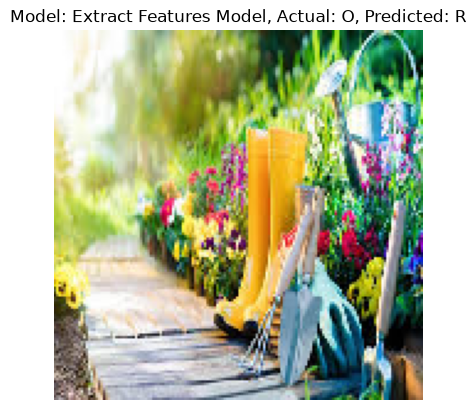

In [25]:
index_to_plot = 1
plot_image_with_title(
    image=test_imgs[index_to_plot].astype("uint8"),
    model_name="Extract Features Model",
    actual_label=test_labels[index_to_plot],
    predicted_label=predictions_extract_feat_model[index_to_plot],
)

### Task 10: Plot a test image using Fine-Tuned Model (index_to_plot = 1)

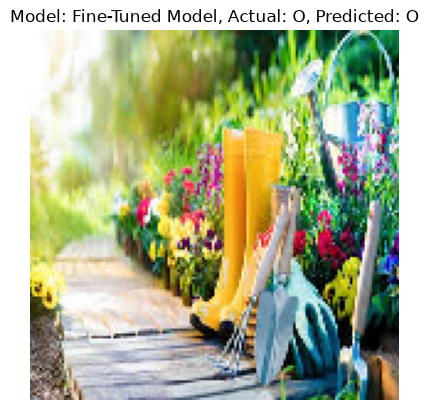

In [26]:
index_to_plot = 1
plot_image_with_title(
    image=test_imgs[index_to_plot].astype("uint8"),
    model_name="Fine-Tuned Model",
    actual_label=test_labels[index_to_plot],
    predicted_label=predictions_fine_tune_model[index_to_plot],
)

## Conclusion
- Both models reuse VGG16's ImageNet knowledge, so they learn from only ~1,200 images.
- The **Fine-Tuned model** also adapts the last VGG16 convolution layer to waste images, so it usually reaches equal or higher validation accuracy than the **Extract Features model**.
- Next steps: train for more steps per epoch, unfreeze more blocks, or add more waste categories.